# code_146 · TabICLv2 classification and regression with explicit model reports

**Book:** section 28.3. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Task inputs and helpers are internal. Ordinary execution is offline and CPU-only after the explicit one-time public checkpoint acquisition in the asset guide; local weights are hash-verified, and missing assets fail with instructions. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_146).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3546;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3546


<a id="tabicl-and-model-report-contract"></a>
 ## Read task support from the actual checkpoint
 Two immutable TabICLv2 checkpoints execute locally: classification and regression. Read the [explicit acquisition guide](../CHAPTER_28_ASSETS.md), then run the acquisition script once; ordinary inference is offline and hash-verified. One hundred generated buildings×8records split60source/20development/20final (480/160/160). The same six numeric fields support two separately defined outcomes: a binary event and a continuous cost summary. A classification context contains event labels; a regression context contains cost labels. No query outcome is admitted. TabICL ensemble sizes1/4 and native histogram leaf counts7/15 are selected independently per task on development evidence, with fixed tree100rounds/rate0.05. Different units/objectives are not pooled into a common score. TabFM is documented from its named primary report, but its restricted default weights are not executed or substituted here.


,task,family,candidate,development_squared_error,ensemble_or_leaf_count
0,classification,TabICLv2,TabICLv2 ensemble 1,0.184191,1
1,classification,TabICLv2,TabICLv2 ensemble 4,0.185594,4
2,classification,Histogram booster,Histogram leaves 7,0.202612,7
3,classification,Histogram booster,Histogram leaves 15,0.208996,15
4,regression,TabICLv2,TabICLv2 ensemble 1,8.780877,1
5,regression,TabICLv2,TabICLv2 ensemble 4,8.810213,4
6,regression,Histogram booster,Histogram leaves 7,11.009207,7
7,regression,Histogram booster,Histogram leaves 15,11.186684,15


,task,family,selected_candidate,final_records,final_squared_error,final_AUC,final_RMSE
0,classification,TabICLv2,TabICLv2 ensemble 1,160,0.181672,0.790500,NaN
1,classification,Histogram booster,Histogram leaves 7,160,0.187165,0.768333,NaN
2,regression,TabICLv2,TabICLv2 ensemble 1,160,10.439239,NaN,3.230981
3,regression,Histogram booster,Histogram leaves 7,160,12.644028,NaN,3.555844


,family,executed_here,record,labelled_target_context
0,TabPFN,False,Native v2 comparison is code_145; package9.2de...,True
1,TabICLv2,True,"Two pinned 20260212 checkpoints, package2.2.0,...",True
2,Google TabFM1.0.0,False,"Primary June30,2026 release; restricted defaul...",True


Uncalibrated nominal80% quantiles: 0.775 8.145297050476074


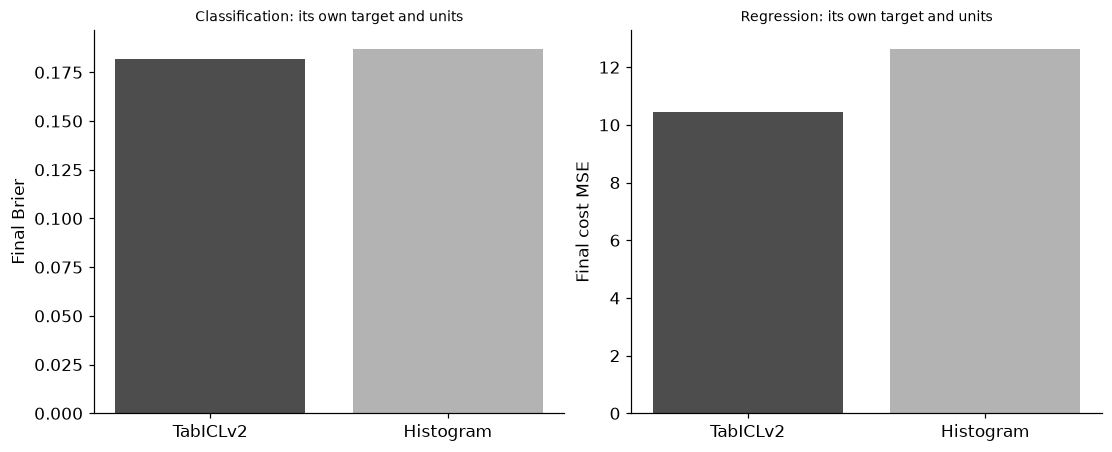

In [2]:
import os,hashlib,importlib.metadata as metadata
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabicl import TabICLClassifier,TabICLRegressor
from sklearn.ensemble import HistGradientBoostingClassifier,HistGradientBoostingRegressor
from sklearn.metrics import brier_score_loss,mean_squared_error,roc_auc_score
VERSIONS['tabicl']=metadata.version('tabicl');VERSIONS['huggingface-hub']=metadata.version('huggingface-hub');ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (p/'examples.json').is_file());revision='4dcd344ece2c00be9e831fdd35bed57b5ad83e19';assets={'classification':('tabicl-classifier-v2-20260212.ckpt','bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0',110368038),'regression':('tabicl-regressor-v2-20260212.ckpt','0db9cb538f114e79026bf08f45f41ad8dd7ad2de2aaca9a5ca8cd3bd9748ae7a',114324594)};paths={}
for task,(filename,digest,size) in assets.items():
    path=ROOT/'build/model-cache/models--jingang--TabICL/snapshots'/revision/filename;assert path.is_file(),'Run python scripts/acquire_chapter28_models.py from companion root';blob=path.read_bytes();assert len(blob)==size and hashlib.sha256(blob).hexdigest()==digest;paths[task]=path
B,R=100,8;building=np.repeat(np.arange(B),R);x=rng.normal(size=(B*R,6));effect=rng.normal(0,.4,B)[building];event=rng.binomial(1,1/(1+np.exp(-(-1+.7*x[:,0]-.6*x[:,1]+.4*x[:,2]**2+effect))));cost=25+5*x[:,0]+3*np.sin(x[:,1])+1.2*x[:,2]**2+effect+rng.normal(0,3,B*R);source=building<60;dev=(building>=60)&(building<80);final=building>=80;targets={'classification':event,'regression':cost};selected={};candidates=[];assessments=[];fitted={}
for task,y in targets.items():
    task_best={}
    for ensemble in [1,4]:
        cls=TabICLClassifier if task=='classification' else TabICLRegressor;model=cls(n_estimators=ensemble,model_path=paths[task],allow_auto_download=False,device='cpu',use_amp=False,use_fa3=False,n_jobs=1,random_state=SEED);model.fit(x[source],y[source]);p=model.predict_proba(x[dev])[:,1] if task=='classification' else model.predict(x[dev]);score=float(np.mean((p-y[dev])**2));name=f'TabICLv2 ensemble {ensemble}';candidates.append({'task':task,'family':'TabICLv2','candidate':name,'development_squared_error':score,'ensemble_or_leaf_count':ensemble});fitted[(task,name)]=model
        if 'TabICLv2' not in task_best or score<task_best['TabICLv2'][0]:task_best['TabICLv2']=(score,name)
    for leaves in [7,15]:
        cls=HistGradientBoostingClassifier if task=='classification' else HistGradientBoostingRegressor;model=cls(max_iter=100,learning_rate=.05,max_leaf_nodes=leaves,min_samples_leaf=15,l2_regularization=1,early_stopping=False,random_state=SEED).fit(x[source],y[source]);p=model.predict_proba(x[dev])[:,1] if task=='classification' else model.predict(x[dev]);score=float(np.mean((p-y[dev])**2));name=f'Histogram leaves {leaves}';candidates.append({'task':task,'family':'Histogram booster','candidate':name,'development_squared_error':score,'ensemble_or_leaf_count':leaves});fitted[(task,name)]=model
        if 'Histogram booster' not in task_best or score<task_best['Histogram booster'][0]:task_best['Histogram booster']=(score,name)
    for family,(_,name) in task_best.items():
        model=fitted[(task,name)];p=model.predict_proba(x[final])[:,1] if task=='classification' else model.predict(x[final]);record={'task':task,'family':family,'selected_candidate':name,'final_records':int(final.sum()),'final_squared_error':float(np.mean((p-y[final])**2))}
        if task=='classification':record['final_AUC']=float(roc_auc_score(y[final],p))
        else:record['final_RMSE']=float(np.sqrt(record['final_squared_error']))
        assessments.append(record);selected[(task,family)]=model
reg=selected[('regression','TabICLv2')];distribution=reg.predict(x[final],output_type=['mean','quantiles'],alphas=[.1,.9]);quantiles=distribution['quantiles'];assert quantiles.shape==(160,2) and np.all(quantiles[:,0]<=quantiles[:,1]);coverage=float(np.mean((cost[final]>=quantiles[:,0])&(cost[final]<=quantiles[:,1])));width=float(np.mean(quantiles[:,1]-quantiles[:,0]));classification=selected[('classification','TabICLv2')];p=classification.predict_proba(x[final]);np.testing.assert_allclose(p.sum(1),np.ones(160),atol=1e-6)
model_reports=[{'family':'TabPFN','executed_here':False,'record':'Native v2 comparison is code_145; package9.2default differs from executed weights','labelled_target_context':True},{'family':'TabICLv2','executed_here':True,'record':'Two pinned 20260212 checkpoints, package2.2.0, separate task labels','labelled_target_context':True},{'family':'Google TabFM1.0.0','executed_here':False,'record':'Primary June30,2026 release; restricted default weights not acquired/executed','labelled_target_context':True}]
RESULTS.update(building_counts=[60,20,20],record_counts=[480,160,160],checkpoint_repository='jingang/TabICL',checkpoint_revision=revision,checkpoint_assets={task:{'filename':a[0],'sha256':a[1],'bytes':a[2]} for task,a in assets.items()},candidate_development=candidates,assessments=assessments,regression_nominal_middle80_quantile_coverage=coverage,regression_mean_quantile_width=width,classification_parameters=sum(p.numel() for p in classification.model_.parameters()),regression_parameters=sum(p.numel() for p in reg.model_.parameters()),model_reports=model_reports);display(pd.DataFrame(candidates));display(pd.DataFrame(assessments));display(pd.DataFrame(model_reports));print('Uncalibrated nominal80% quantiles:',coverage,width)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,task in zip(axes,targets):
    rr=[r for r in assessments if r['task']==task];ax.bar(['TabICLv2','Histogram'],[r['final_squared_error'] for r in rr],color=['.3','.7']);ax.set(ylabel='Final Brier' if task=='classification' else 'Final cost MSE',title=task.capitalize()+': its own target and units')
plt.show()


<a id="family-reports-and-context"></a>
 ## Zero new-task gradient updates still use new-task supervision
 Native wrappers fit encoders, normalization and ensemble context using admitted source rows. That work is distinct from the checkpoint's upstream pretraining and from optional parameter fine-tuning. The classification/regression wrappers select separately because one models discrete events and the other continuous cost. Quantiles are requested through the regressor's actual distribution interface and assessed on independent final buildings; their nominal levels do not imply calibrated coverage. Public benchmark reports, original-paper compute, licences and checkpoint-specific limits remain separate from these local results. Google's named TabFM supports classification/regression via labelled context according to its primary source, but no TabFM output or performance is fabricated here. Architectural similarity, an available Python interface or a missing restricted checkpoint never licenses replacing it with another model under the same name.


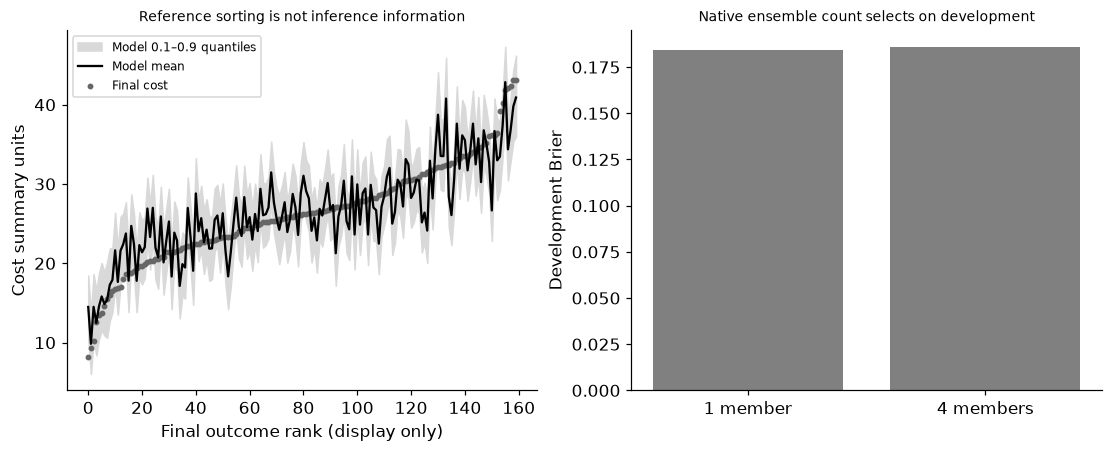

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));order=np.argsort(cost[final]);positions=np.arange(len(order));axes[0].fill_between(positions,quantiles[order,0],quantiles[order,1],color='.85',label='Model 0.1–0.9 quantiles');axes[0].plot(positions,distribution['mean'][order],color='black',label='Model mean');axes[0].scatter(positions,cost[final][order],s=8,color='.4',label='Final cost');axes[0].set(xlabel='Final outcome rank (display only)',ylabel='Cost summary units',title='Reference sorting is not inference information');axes[0].legend(fontsize=8);rr=[r for r in candidates if r['family']=='TabICLv2' and r['task']=='classification'];axes[1].bar(['1 member','4 members'],[r['development_squared_error'] for r in rr],color='.5');axes[1].set(ylabel='Development Brier',title='Native ensemble count selects on development');plt.show()
assert all(np.isfinite(r['final_squared_error']) for r in assessments)


In [4]:
summary={'example_id':'code_146','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned TabICLv2 classifier and regressor', 'separate labelled-context task heads', 'checkpoint and source-package identity audit', 'development-selected native ensemble and tree controls', 'regression quantile assessment without calibration guarantee'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned TabICLv2 classifier and regressor", "separate labelled-context task heads", "checkpoint and source-package identity audit", "development-selected native ensemble and tree controls", "regression quantile assessment without calibration guarantee"], "elapsed_seconds": 3.904, "example_id": "code_146", "hardware": "Darwin arm64 CPU", "results": {"assessments": [{"family": "TabICLv2", "final_AUC": 0.7905, "final_records": 160, "final_squared_error": 0.18167194293805716, "selected_candidate": "TabICLv2 ensemble 1", "task": "classification"}, {"family": "Histogram booster", "final_AUC": 0.7683333333333333, "final_records": 160, "final_squared_error": 0.18716530611541135, "selected_candidate": "Histogram leaves 7", "task": "classification"}, {"family": "TabICLv2", "final_RMSE": 3.2309810857789967, "final_records": 160, "final_squared_error": 10.439238776661623, "selected_candidate": "TabICLv2 ensemble 1", "task": "regression"}, {"